In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Amazon Sale Report.csv", low_memory=False)
print(df.shape)   # rows and columns
df.head()         # first 5 rows

(128976, 21)


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Category,Size,Courier Status,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B,fulfilled-by,New,PendingS
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,T-shirt,S,On the Way,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,False,Easy Ship,NaN,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,Shirt,3XL,Shipped,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,False,Easy Ship,NaN,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,Shirt,XL,Shipped,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,True,NaN,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,Blazzer,L,On the Way,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,False,Easy Ship,NaN,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,Trousers,3XL,Shipped,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,False,NaN,NaN,NaN


In [2]:
df = df.drop(columns=["index", "New", "PendingS"])

In [3]:
df.columns = df.columns.str.strip()

In [5]:
df["Date"] = pd.to_datetime(df["Date"], format="%m-%d-%y")

ValueError: unconverted data remains when parsing with format "%m-%d-%y": "22". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [6]:
print(df["Date"].head())

0    04-30-22
1    04-30-22
2    04-30-22
3    04-30-22
4    04-30-22
Name: Date, dtype: str


In [7]:
lengths = df["Date"].str.len()
print(lengths.value_counts())
print(df.loc[lengths != 8, "Date"].head(10))

Date
8     73867
10    55109
Name: count, dtype: int64
29926    04-12-2022
29927    04-12-2022
29928    04-12-2022
29929    04-12-2022
29930    04-12-2022
29931    04-12-2022
29932    04-12-2022
29933    04-12-2022
29934    04-12-2022
29935    04-12-2022
Name: Date, dtype: str


In [8]:
d1 = pd.to_datetime(df["Date"], format="%m-%d-%y", errors="coerce")
d2 = pd.to_datetime(df["Date"], format="%m-%d-%Y", errors="coerce")
df["Date"] = d1.fillna(d2)

In [9]:
print(df["Date"].dtype)
print(df["Date"].min(), df["Date"].max())
print(df["Date"].isna().sum())

datetime64[us]
2022-03-31 00:00:00 2022-06-29 00:00:00
0


In [10]:
df["Category"] = df["Category"].replace("Blazzer", "Blazer")
df["Month"] = df["Date"].dt.to_period("M").astype(str)
sales = df[(df["Status"] != "Cancelled") & (df["Amount"] > 0)]

Total revenue: 71671747.0
Total orders: 100600
Average order value: 663.1974368464884


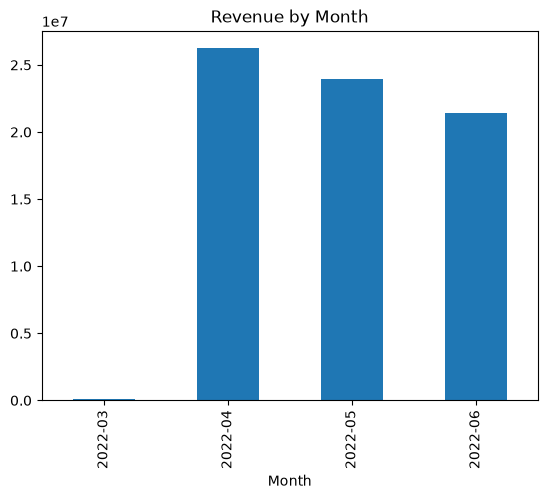

In [11]:
print("Total revenue:", sales["Amount"].sum())
print("Total orders:", sales["Order ID"].nunique())
print("Average order value:", sales["Amount"].mean())

sales.groupby("Month")["Amount"].sum().plot(kind="bar", title="Revenue by Month")
plt.show()


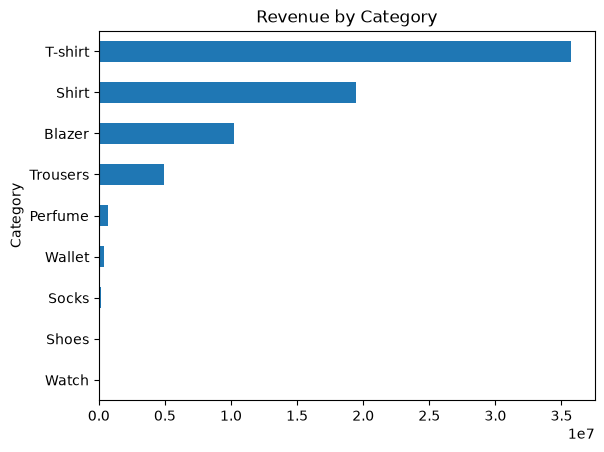

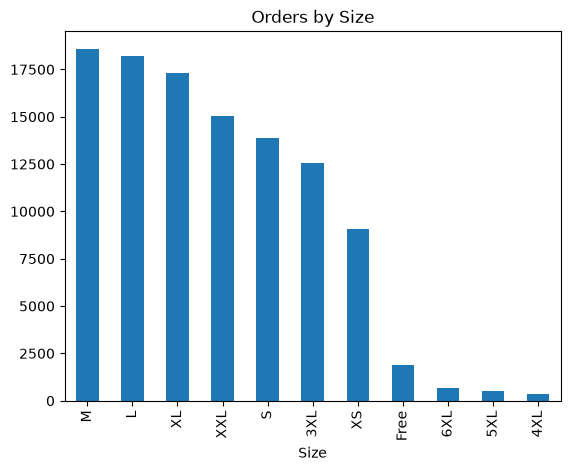

In [12]:
sales.groupby("Category")["Amount"].sum().sort_values().plot(kind="barh", title="Revenue by Category")
plt.show()

sales["Size"].value_counts().plot(kind="bar", title="Orders by Size")
plt.show()

In [13]:
# cancellation rate (%) for Amazon vs Merchant
print(df.groupby("Fulfilment")["Status"].apply(lambda s: (s == "Cancelled").mean() * 100))

# revenue and orders by fulfilment type
print(sales.groupby("Fulfilment")["Amount"].agg(["count", "sum", "mean"]))


Fulfilment
Amazon      12.790788
Merchant    17.469373
Name: Status, dtype: float64
            count         sum        mean
Fulfilment                               
Amazon      76492  50598970.0  661.493620
Merchant    31578  21072777.0  667.324625


In [14]:
# business buyers vs normal buyers
print(sales.groupby("B2B")["Amount"].agg(["count", "mean"]))

# low / medium / high order value
sales["Value Group"] = pd.qcut(sales["Amount"], 3, labels=["Low", "Medium", "High"])
print(sales["Value Group"].value_counts())


        count        mean
B2B                      
False  107272  662.913789
True      798  701.327068
Value Group
Low       37365
High      35975
Medium    34730
Name: count, dtype: int64


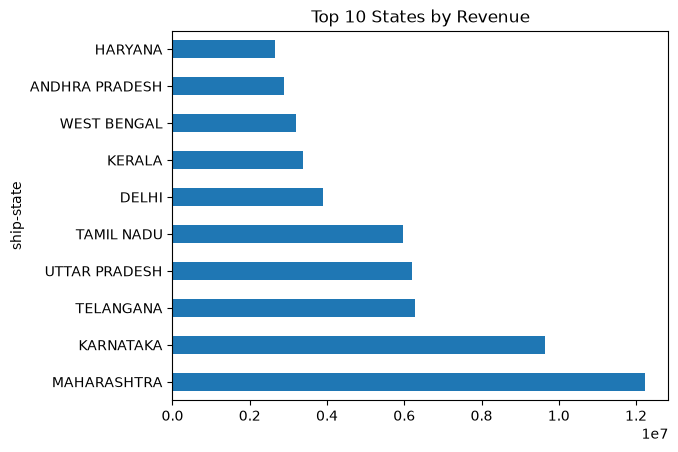

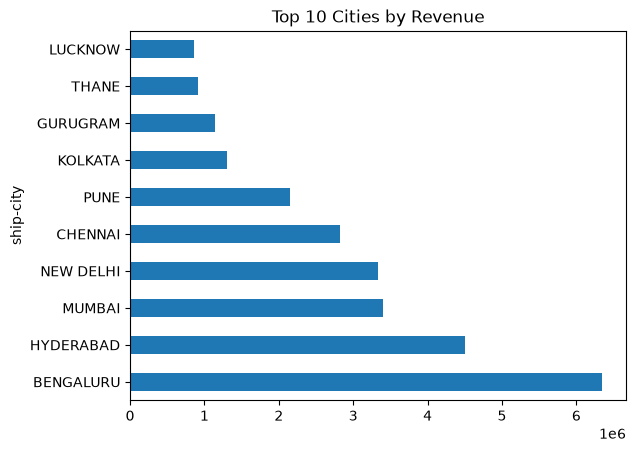

In [15]:
sales.groupby("ship-state")["Amount"].sum().sort_values(ascending=False).head(10).plot(
    kind="barh", title="Top 10 States by Revenue")
plt.show()

sales.groupby("ship-city")["Amount"].sum().sort_values(ascending=False).head(10).plot(
    kind="barh", title="Top 10 Cities by Revenue")
plt.show()

In [16]:
plt.savefig("revenue_by_month.png", bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

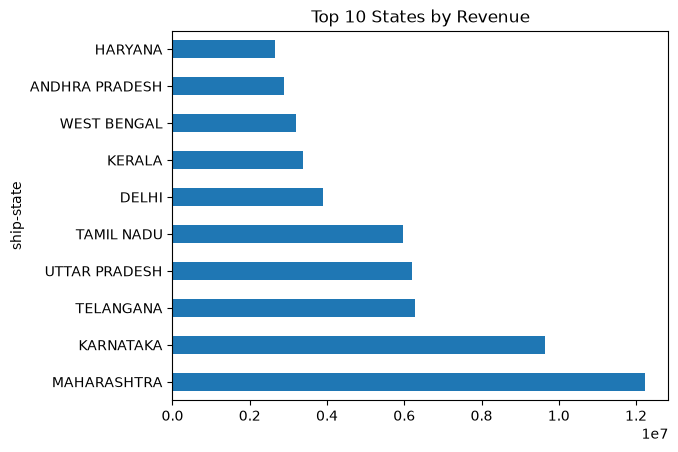

<Axes: title={'center': 'Top 10 Cities by Revenue'}, ylabel='ship-city'>

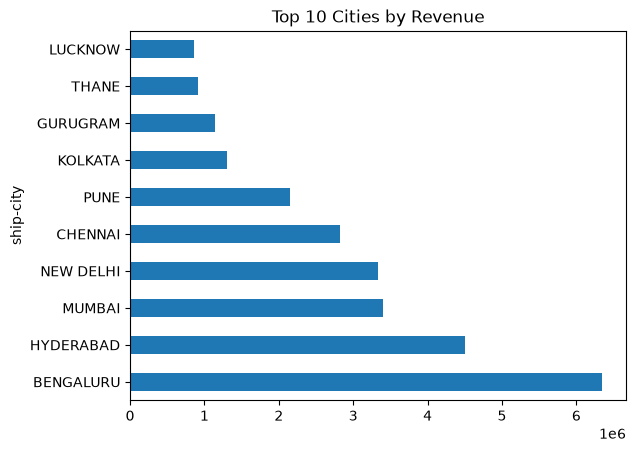

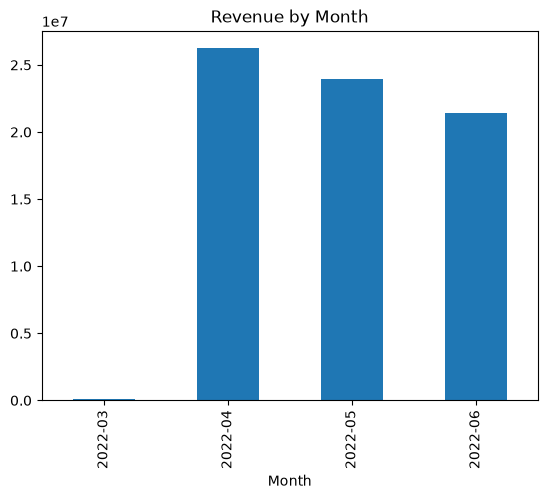

In [18]:
sales.groupby("Month")["Amount"].sum().plot(kind="bar", title="Revenue by Month")
plt.savefig("revenue_by_month.png", bbox_inches="tight")
plt.show()

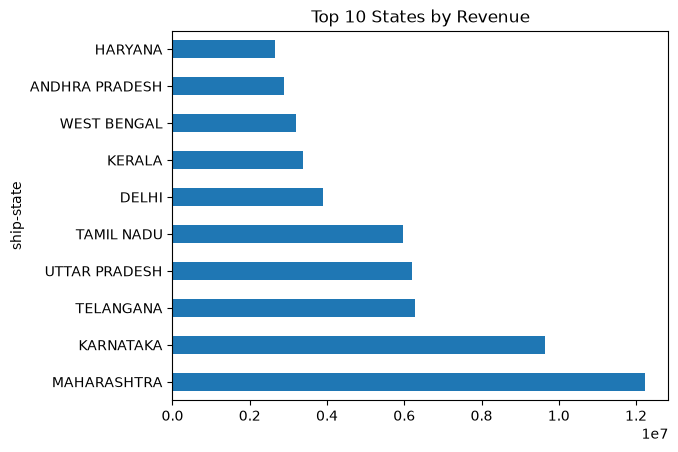

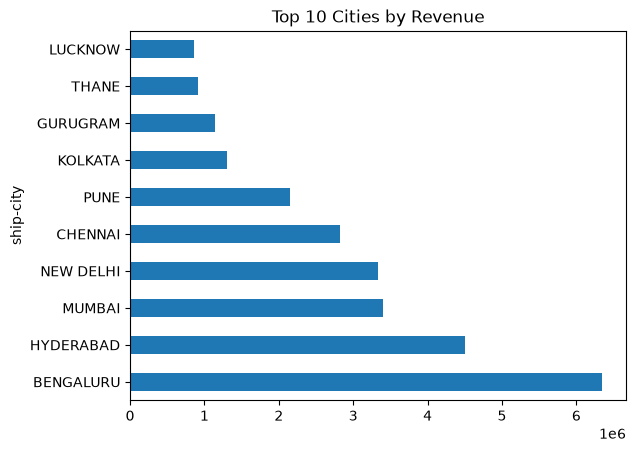

In [19]:
sales.groupby("ship-state")["Amount"].sum().sort_values(ascending=False).head(10).plot(
    kind="barh", title="Top 10 States by Revenue")
plt.savefig("Top_10_States_by_Revenue.png", bbox_inches="tight")   
plt.show()

sales.groupby("ship-city")["Amount"].sum().sort_values(ascending=False).head(10).plot(
    kind="barh", title="Top 10 Cities by Revenue")
plt.savefig("Top_10_cities_by_Revenue.png", bbox_inches="tight")
plt.show()



FileNotFoundError: [Errno 2] No such file or directory: 'charts/01_revenue_by_month.png'

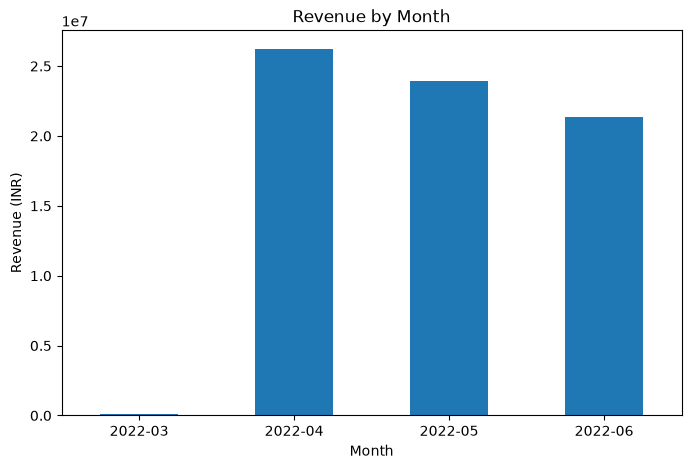

In [20]:
plt.figure(figsize=(8, 5))
monthly = sales.groupby("Month")["Amount"].sum()
monthly.plot(kind="bar", title="Revenue by Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=0)
plt.savefig("charts/01_revenue_by_month.png", bbox_inches="tight")
plt.show()
plt.close()
monthly.round().to_csv("tables/revenue_by_month.csv")

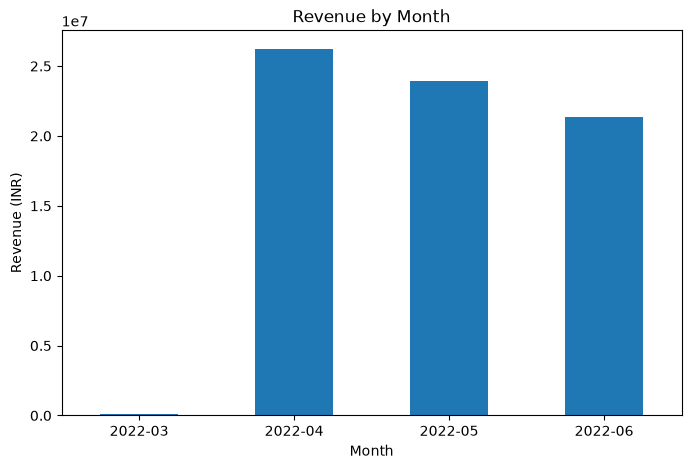

OSError: Cannot save file into a non-existent directory: 'tables'

In [21]:
plt.figure(figsize=(8, 5))
monthly = sales.groupby("Month")["Amount"].sum()
monthly.plot(kind="bar", title="Revenue by Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=0)
plt.savefig("charts/01_revenue_by_month.png", bbox_inches="tight")
plt.show()
plt.close()
monthly.round().to_csv("tables/revenue_by_month.csv")

In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("charts", exist_ok=True)
os.makedirs("tables", exist_ok=True)

sales = sales.copy()   # avoids warnings when we add columns

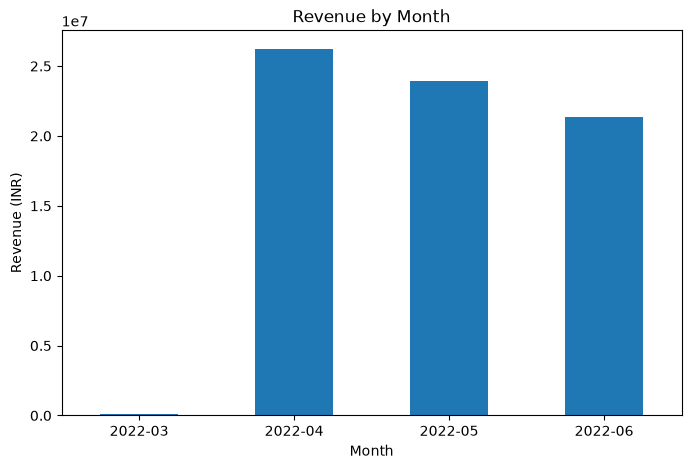

In [23]:
plt.figure(figsize=(8, 5))
monthly = sales.groupby("Month")["Amount"].sum()
monthly.plot(kind="bar", title="Revenue by Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=0)
plt.savefig("charts/01_revenue_by_month.png", bbox_inches="tight")
plt.show()
plt.close()
monthly.round().to_csv("tables/revenue_by_month.csv")

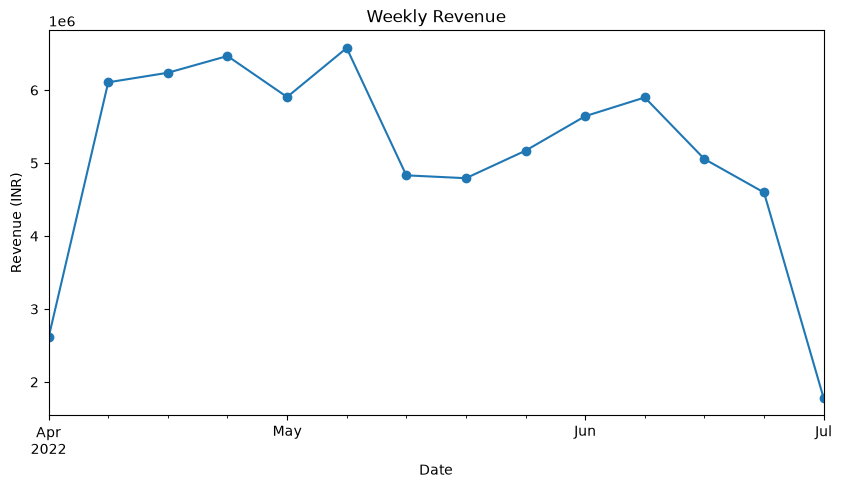

In [24]:
plt.figure(figsize=(10, 5))
weekly = sales.set_index("Date")["Amount"].resample("W").sum()
weekly.plot(kind="line", marker="o", title="Weekly Revenue")
plt.ylabel("Revenue (INR)")
plt.savefig("charts/02_weekly_revenue.png", bbox_inches="tight")
plt.show()
plt.close()
weekly.round().to_csv("tables/weekly_revenue.csv")

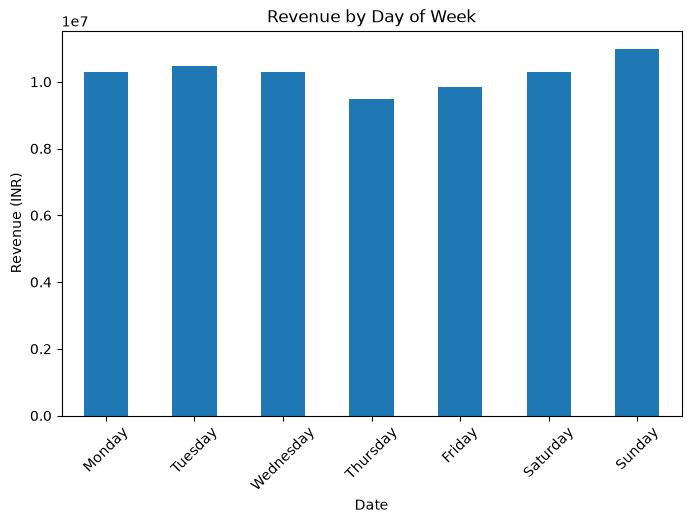

In [25]:
plt.figure(figsize=(8, 5))
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = sales.groupby(sales["Date"].dt.day_name())["Amount"].sum().reindex(order)
by_day.plot(kind="bar", title="Revenue by Day of Week")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.savefig("charts/03_revenue_by_weekday.png", bbox_inches="tight")
plt.show()
plt.close()
by_day.round().to_csv("tables/revenue_by_weekday.csv")

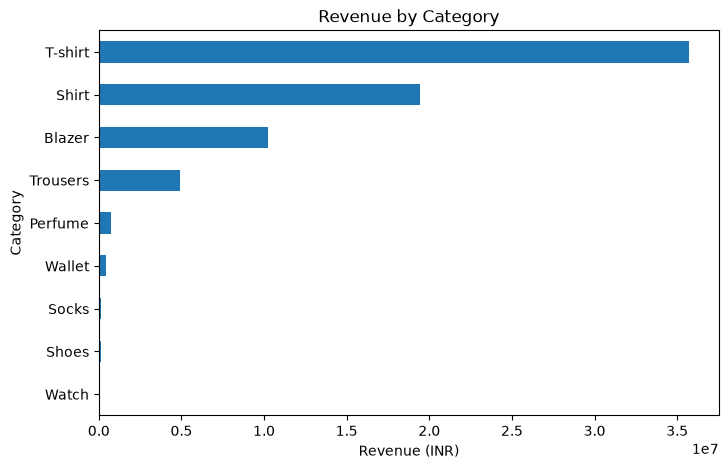

In [26]:
plt.figure(figsize=(8, 5))
cat_rev = sales.groupby("Category")["Amount"].sum().sort_values()
cat_rev.plot(kind="barh", title="Revenue by Category")
plt.xlabel("Revenue (INR)")
plt.savefig("charts/04_revenue_by_category.png", bbox_inches="tight")
plt.show()
plt.close()
cat_rev.sort_values(ascending=False).round().to_csv("tables/revenue_by_category.csv")

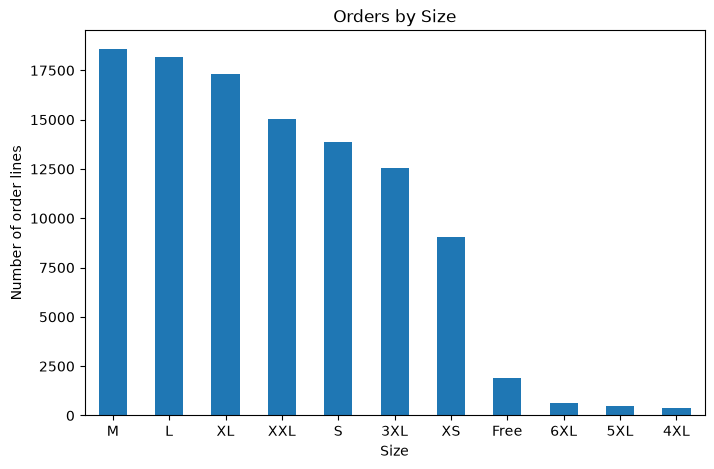

In [27]:
plt.figure(figsize=(8, 5))
size_counts = sales["Size"].value_counts()
size_counts.plot(kind="bar", title="Orders by Size")
plt.ylabel("Number of order lines")
plt.xticks(rotation=0)
plt.savefig("charts/05_orders_by_size.png", bbox_inches="tight")
plt.show()
plt.close()
size_counts.to_csv("tables/orders_by_size.csv")

In [28]:
pd.crosstab(sales["Category"], sales["Size"]).to_csv("tables/category_by_size.csv")

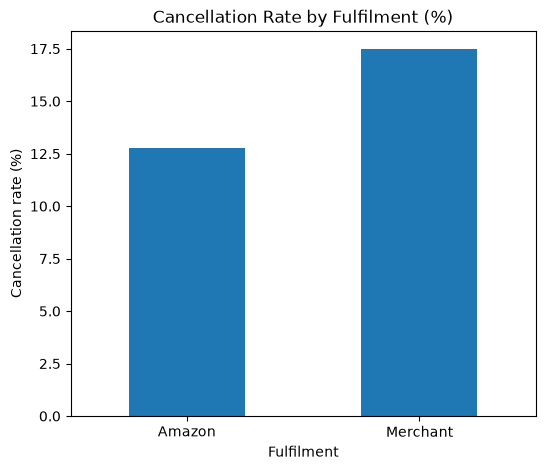

In [29]:
plt.figure(figsize=(6, 5))
cancel_ful = df.groupby("Fulfilment")["Status"].apply(lambda s: (s == "Cancelled").mean() * 100)
cancel_ful.plot(kind="bar", title="Cancellation Rate by Fulfilment (%)")
plt.ylabel("Cancellation rate (%)")
plt.xticks(rotation=0)
plt.savefig("charts/06_cancellation_by_fulfilment.png", bbox_inches="tight")
plt.show()
plt.close()
cancel_ful.round(1).to_csv("tables/cancellation_by_fulfilment.csv")

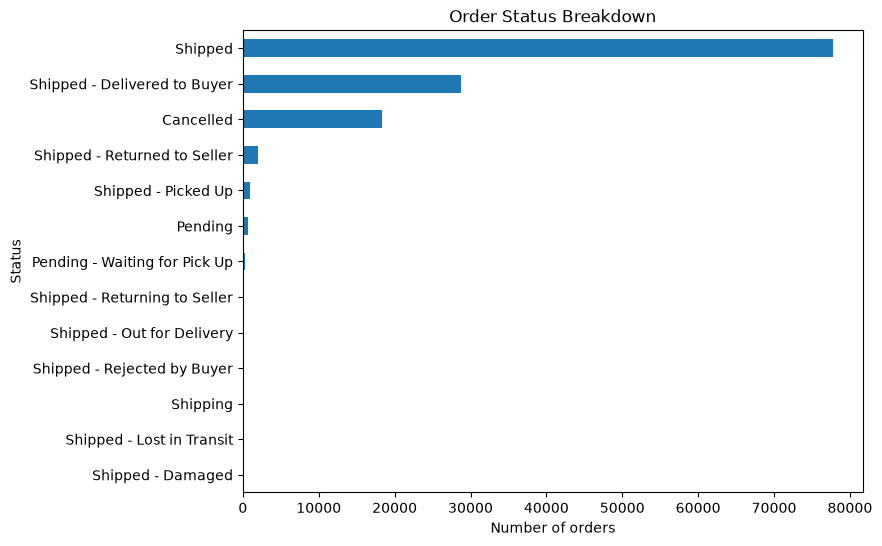

In [30]:
plt.figure(figsize=(8, 6))
status_counts = df["Status"].value_counts().sort_values()
status_counts.plot(kind="barh", title="Order Status Breakdown")
plt.xlabel("Number of orders")
plt.savefig("charts/07_status_breakdown.png", bbox_inches="tight")
plt.show()
plt.close()
status_counts.to_csv("tables/status_breakdown.csv")

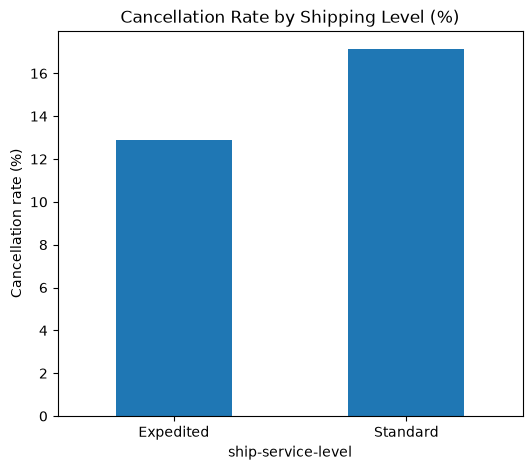

In [31]:
plt.figure(figsize=(6, 5))
cancel_ship = df.groupby("ship-service-level")["Status"].apply(lambda s: (s == "Cancelled").mean() * 100)
cancel_ship.plot(kind="bar", title="Cancellation Rate by Shipping Level (%)")
plt.ylabel("Cancellation rate (%)")
plt.xticks(rotation=0)
plt.savefig("charts/08_cancellation_by_shipping.png", bbox_inches="tight")
plt.show()
plt.close()
cancel_ship.round(1).to_csv("tables/cancellation_by_shipping.csv")

In [32]:
sales.groupby("Fulfilment")["Amount"].agg(["count", "sum", "mean"]).round().to_csv("tables/revenue_by_fulfilment.csv")

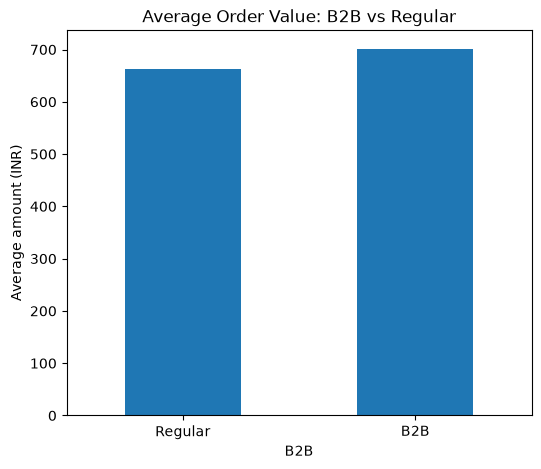

In [34]:
plt.figure(figsize=(6, 5))
b2b = sales.groupby("B2B")["Amount"].mean().rename({False: "Regular", True: "B2B"})
b2b.plot(kind="bar", title="Average Order Value: B2B vs Regular")
plt.ylabel("Average amount (INR)")
plt.xticks(rotation=0)
plt.savefig("charts/09_b2b_vs_regular.png", bbox_inches="tight")
plt.show()
plt.close()
sales.groupby("B2B")["Amount"].agg(["count", "mean"]).round().to_csv("tables/b2b_vs_regular.csv")

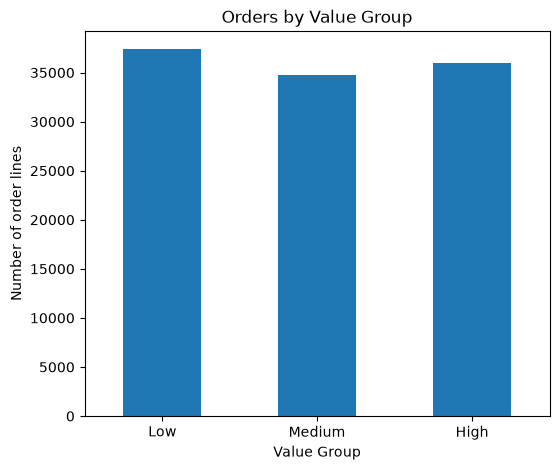

In [35]:
sales["Value Group"] = pd.qcut(sales["Amount"], 3, labels=["Low", "Medium", "High"])

plt.figure(figsize=(6, 5))
vg = sales["Value Group"].value_counts().reindex(["Low", "Medium", "High"])
vg.plot(kind="bar", title="Orders by Value Group")
plt.ylabel("Number of order lines")
plt.xticks(rotation=0)
plt.savefig("charts/10_value_groups.png", bbox_inches="tight")
plt.show()
plt.close()
pd.crosstab(sales["Category"], sales["Value Group"]).to_csv("tables/category_by_value_group.csv")

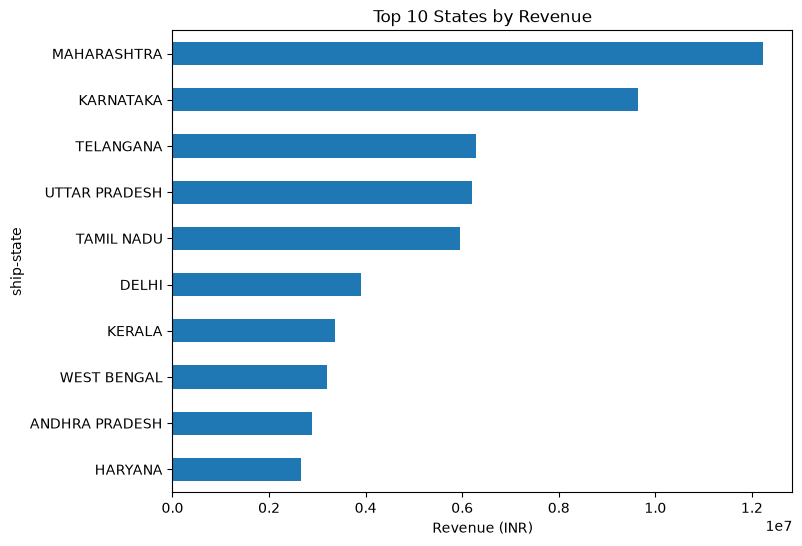

In [36]:
plt.figure(figsize=(8, 6))
top_states = sales.groupby("ship-state")["Amount"].sum().sort_values(ascending=False).head(10)
top_states.sort_values().plot(kind="barh", title="Top 10 States by Revenue")
plt.xlabel("Revenue (INR)")
plt.savefig("charts/11_top_states.png", bbox_inches="tight")
plt.show()
plt.close()
top_states.round().to_csv("tables/top_10_states.csv")

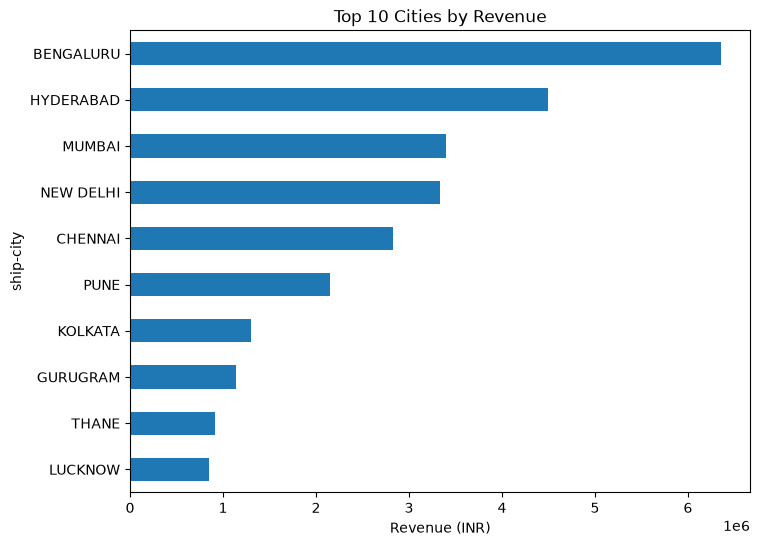

In [37]:
plt.figure(figsize=(8, 6))
top_cities = sales.groupby("ship-city")["Amount"].sum().sort_values(ascending=False).head(10)
top_cities.sort_values().plot(kind="barh", title="Top 10 Cities by Revenue")
plt.xlabel("Revenue (INR)")
plt.savefig("charts/12_top_cities.png", bbox_inches="tight")
plt.show()
plt.close()
top_cities.round().to_csv("tables/top_10_cities.csv")

In [38]:
total_rev = round(sales["Amount"].sum())
total_orders = sales["Order ID"].nunique()
avg_order = round(sales["Amount"].mean())
cancel_total = round((df["Status"] == "Cancelled").mean() * 100, 1)

with open("tables/key_numbers.txt", "w") as f:
    f.write(f"Total revenue (INR): {total_rev}\n")
    f.write(f"Total orders: {total_orders}\n")
    f.write(f"Average order value (INR): {avg_order}\n")
    f.write(f"Overall cancellation rate (%): {cancel_total}\n")

print(open("tables/key_numbers.txt").read())


Total revenue (INR): 71671747
Total orders: 100600
Average order value (INR): 663
Overall cancellation rate (%): 14.2

